# AI & ML Internship – Task 1
## Data Cleaning & Preprocessing

### Objective
The objective is to clean and prepare raw data for machine learning.

### Dataset
**Employee Attrition Dataset** – a self-contained dataset created for this task with numerical and categorical features, missing values, and deliberate numerical outliers.

### Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

### Workflow
1. Import and explore the dataset
2. Check nulls and data types
3. Handle missing values
4. Encode categorical variables
5. Detect and remove outliers
6. Standardize numerical features
7. Validate the final dataset


## 1. Import Libraries

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Import the Dataset

In [33]:
DATA_PATH = "../data/employee_attrition_raw.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (600, 14)


,Employee_ID,Age,Gender,Department,Education,Job_Level,Years_At_Company,Monthly_Income,Job_Satisfaction,Weekly_Hours,Projects_Handled,Remote_Work,Performance_Rating,Attrition
0,EMP1001,30.0,Male,Sales,Master,Lead,3.5,92131.0,2.0,38.8,2.0,No,Average,No
1,EMP1002,32.0,Male,Operations,High School,Senior,3.0,83367.0,5.0,43.9,4.0,No,Low,No
2,EMP1003,21.0,Male,Finance,High School,Mid,1.2,72219.0,5.0,44.8,3.0,No,High,No
3,EMP1004,28.0,Male,HR,Bachelor,Mid,2.4,58122.0,1.0,61.5,2.0,Yes,Average,No
4,EMP1005,42.0,Male,Engineering,Bachelor,Mid,5.1,111567.0,1.0,42.9,3.0,Yes,Average,No


## 3. Explore Basic Information

In [34]:
print("Shape:", df.shape)

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nStatistical summary:")
display(df.describe(include="all").T)


Shape: (600, 14)

Data types:


,dtype
Employee_ID,object
Age,float64
Gender,object
Department,object
Education,object
Job_Level,object
Years_At_Company,float64
Monthly_Income,float64
Job_Satisfaction,float64
Weekly_Hours,float64



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Employee_ID,600,600,EMP1001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,579.0,NaN,NaN,NaN,34.231434,7.41258,21.0,29.0,34.0,39.0,59.0
Gender,588,2,Male,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,588,6,Engineering,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,585,4,Bachelor,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Level,588,4,Mid,252,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Years_At_Company,582.0,NaN,NaN,NaN,3.89811,2.571681,0.1,2.0,3.4,5.3,20.0
Monthly_Income,585.0,NaN,NaN,NaN,76169.295726,54574.173444,22000.0,46837.0,66387.0,90506.0,750000.0
Job_Satisfaction,582.0,NaN,NaN,NaN,2.986254,1.38587,1.0,2.0,3.0,4.0,5.0
Weekly_Hours,585.0,NaN,NaN,NaN,44.04359,7.603912,30.0,40.0,43.6,47.8,110.0


## 4. Missing Value Analysis

Missing values by column:


,missing_count
Age,21
Years_At_Company,18
Job_Satisfaction,18
Education,15
Monthly_Income,15
Weekly_Hours,15
Gender,12
Department,12
Job_Level,12
Remote_Work,12


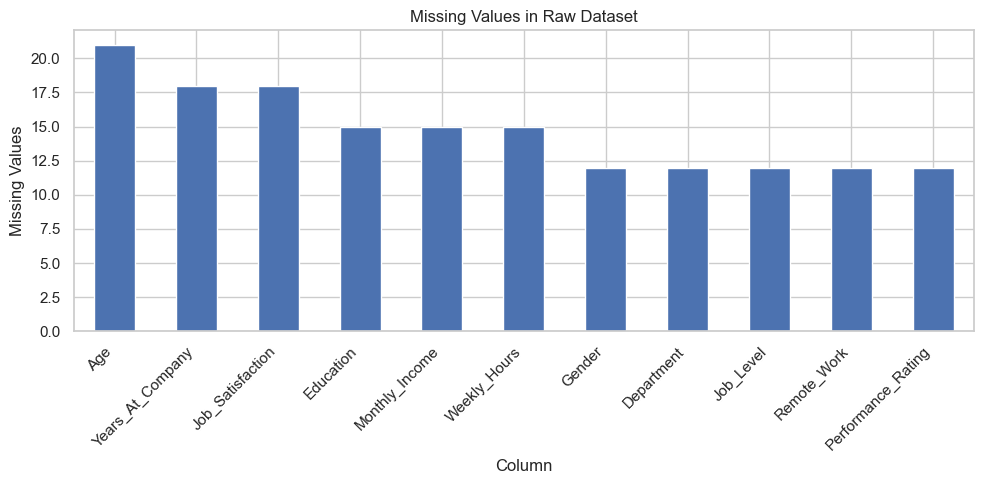

In [35]:
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]

print("Missing values by column:")
display(missing.to_frame("missing_count"))

plt.figure(figsize=(10, 5))
missing.plot(kind="bar")
plt.title("Missing Values in Raw Dataset")
plt.xlabel("Column")
plt.ylabel("Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Missing-value strategy

- Numerical columns: **median imputation**
- Categorical columns: **mode imputation**
- The median is less sensitive to extreme numerical values than the mean.
- The mode is appropriate for replacing a missing categorical value with the most frequent category.


In [36]:
df_clean = df.copy()

numerical_cols = [
    "Age", "Years_At_Company", "Monthly_Income",
    "Job_Satisfaction", "Weekly_Hours", "Projects_Handled"
]

categorical_cols = [
    "Gender", "Department", "Education",
    "Job_Level", "Remote_Work", "Performance_Rating"
]

for col in numerical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Total missing values after imputation:",
      int(df_clean.isnull().sum().sum()))


Total missing values after imputation: 0


## 5. Remove Identifier

In [37]:
# Employee_ID is an identifier and is not useful as a numerical ML feature.
df_clean = df_clean.drop(columns=["Employee_ID"])
display(df_clean.head())


,Age,Gender,Department,Education,Job_Level,Years_At_Company,Monthly_Income,Job_Satisfaction,Weekly_Hours,Projects_Handled,Remote_Work,Performance_Rating,Attrition
0,30.0,Male,Sales,Master,Lead,3.5,92131.0,2.0,38.8,2.0,No,Average,No
1,32.0,Male,Operations,High School,Senior,3.0,83367.0,5.0,43.9,4.0,No,Low,No
2,21.0,Male,Finance,High School,Mid,1.2,72219.0,5.0,44.8,3.0,No,High,No
3,28.0,Male,HR,Bachelor,Mid,2.4,58122.0,1.0,61.5,2.0,Yes,Average,No
4,42.0,Male,Engineering,Bachelor,Mid,5.1,111567.0,1.0,42.9,3.0,Yes,Average,No


## 6. Categorical Feature Encoding

Categorical variables need numerical representation for most machine-learning algorithms.

**One-hot encoding** is used for the categorical features. `drop_first=True` removes one reference category to avoid redundant dummy columns.


In [38]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", df_encoded.shape)
display(df_encoded.head())


Shape after encoding: (600, 22)


,Age,Years_At_Company,Monthly_Income,Job_Satisfaction,Weekly_Hours,Projects_Handled,Attrition,Gender_Male,Department_Finance,Department_HR,Department_Marketing,Department_Operations,Department_Sales,Education_High School,Education_Master,Education_PhD,Job_Level_Lead,Job_Level_Mid,Job_Level_Senior,Remote_Work_Yes,Performance_Rating_High,Performance_Rating_Low
0,30.0,3.5,92131.0,2.0,38.8,2.0,No,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0
1,32.0,3.0,83367.0,5.0,43.9,4.0,No,1,0,0,0,1,0,1,0,0,0,0,1,0,0,1
2,21.0,1.2,72219.0,5.0,44.8,3.0,No,1,1,0,0,0,0,1,0,0,0,1,0,0,1,0
3,28.0,2.4,58122.0,1.0,61.5,2.0,No,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0
4,42.0,5.1,111567.0,1.0,42.9,3.0,No,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0


## 7. Outlier Detection

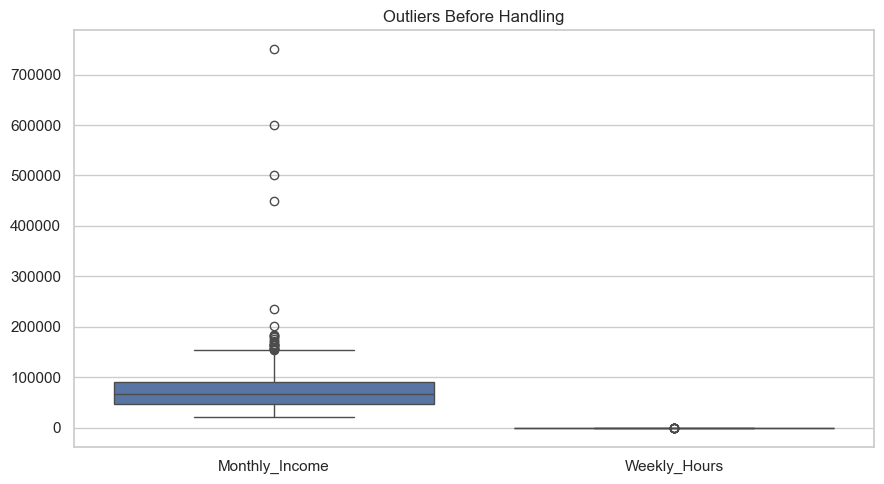

In [39]:
outlier_cols = ["Monthly_Income", "Weekly_Hours"]

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean[outlier_cols])
plt.title("Outliers Before Handling")
plt.tight_layout()
plt.show()


### IQR Method

For each selected numerical feature:

- Q1 = 25th percentile
- Q3 = 75th percentile
- IQR = Q3 − Q1
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Values outside the bounds are treated as potential outliers.


In [40]:
before_rows = len(df_encoded)
mask = pd.Series(True, index=df_encoded.index)

for col in outlier_cols:
    q1 = df_encoded[col].quantile(0.25)
    q3 = df_encoded[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    print(f"{col}:")
    print(f"  Lower bound = {lower_bound:.2f}")
    print(f"  Upper bound = {upper_bound:.2f}")

    mask &= df_encoded[col].between(lower_bound, upper_bound)

df_no_outliers = df_encoded.loc[mask].copy()

print("\nRows before outlier handling:", before_rows)
print("Rows after outlier handling: ", len(df_no_outliers))
print("Rows removed:                ", before_rows - len(df_no_outliers))


Monthly_Income:
  Lower bound = -17006.00
  Upper bound = 154078.00
Weekly_Hours:
  Lower bound = 28.81
  Upper bound = 58.91

Rows before outlier handling: 600
Rows after outlier handling:  568
Rows removed:                 32


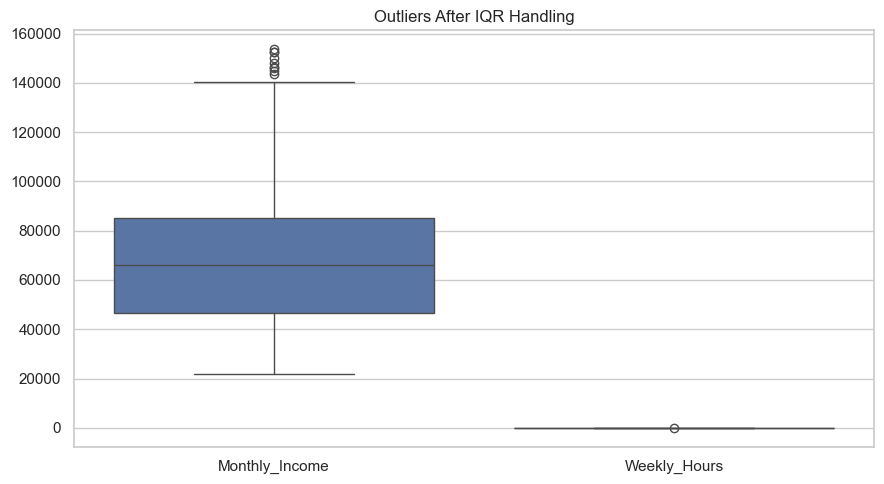

In [41]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_no_outliers[outlier_cols])
plt.title("Outliers After IQR Handling")
plt.tight_layout()
plt.show()


## 8. Standardization

Standardization transforms numerical features to approximately mean 0 and standard deviation 1.

**Normalization** generally rescales values to a fixed range such as 0–1, while **standardization** centers and scales based on the mean and standard deviation.


In [42]:
scaler = StandardScaler()

df_final = df_no_outliers.copy()

df_final[numerical_cols] = scaler.fit_transform(
    df_final[numerical_cols]
)

display(df_final.head())


,Age,Years_At_Company,Monthly_Income,Job_Satisfaction,Weekly_Hours,Projects_Handled,Attrition,Gender_Male,Department_Finance,Department_HR,Department_Marketing,Department_Operations,Department_Sales,Education_High School,Education_Master,Education_PhD,Job_Level_Lead,Job_Level_Mid,Job_Level_Senior,Remote_Work_Yes,Performance_Rating_High,Performance_Rating_Low
0,-0.591073,-0.154024,0.797527,-0.727996,-0.827289,-0.975635,No,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0
1,-0.318122,-0.350976,0.492345,1.475388,0.083370,0.059212,No,1,0,0,0,1,0,1,0,0,0,0,1,0,0,1
2,-1.819351,-1.060002,0.104147,1.475388,0.244075,-0.458212,No,1,1,0,0,0,0,1,0,0,0,1,0,0,1,0
4,1.046632,0.476221,1.474332,-1.462458,-0.095190,-0.458212,No,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0
5,1.729009,-0.902440,0.000342,-1.462458,-1.112987,0.576636,No,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0


## 9. Final Validation

In [43]:
print("Final shape:", df_final.shape)

print("\nRemaining missing values:")
display(df_final.isnull().sum().to_frame("missing_count"))

print("\nRemaining object columns:")
print(df_final.select_dtypes(include="object").columns.tolist())

print("\nFinal numerical summary:")
display(df_final[numerical_cols].describe().T)


Final shape: (568, 22)

Remaining missing values:


,missing_count
Age,0
Years_At_Company,0
Monthly_Income,0
Job_Satisfaction,0
Weekly_Hours,0
Projects_Handled,0
Attrition,0
Gender_Male,0
Department_Finance,0
Department_HR,0



Remaining object columns:
['Attrition']

Final numerical summary:


,count,mean,std,min,25%,50%,75%,max
Age,568.0,-2.720828e-16,1.000881,-1.819351,-0.727548,-0.045171,0.637206,3.366713
Years_At_Company,568.0,-2.892835e-16,1.000881,-1.493295,-0.744879,-0.193415,0.486068,6.345378
Monthly_Income,568.0,-8.287580e-17,1.000881,-1.644589,-0.787989,-0.108529,0.561241,2.938954
Job_Satisfaction,568.0,3.127389e-18,1.000881,-1.462458,-0.727996,0.006465,0.740927,1.475388
Weekly_Hours,568.0,-1.563694e-17,1.000881,-2.398624,-0.639801,0.029802,0.677085,2.654645
Projects_Handled,568.0,6.254778e-17,1.000881,-2.010483,-0.458212,0.059212,0.576636,3.681178


## 10. Correlation Heatmap

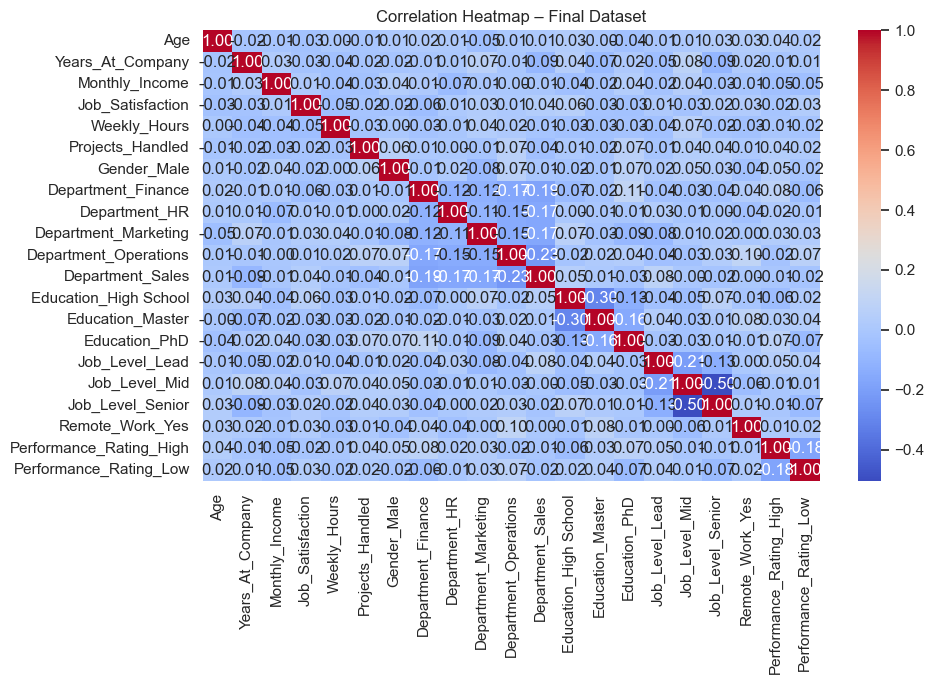

In [44]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    df_final.select_dtypes(include=np.number).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap – Final Dataset")
plt.tight_layout()
plt.show()


## 11. Before vs After Summary

In [45]:
summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Total missing values",
        "Object/categorical columns",
        "Numerical features standardized"
    ],
    "Before": [
        len(df),
        df.shape[1],
        int(df.isnull().sum().sum()),
        len(df.select_dtypes(include="object").columns),
        "No"
    ],
    "After": [
        len(df_final),
        df_final.shape[1],
        int(df_final.isnull().sum().sum()),
        len(df_final.select_dtypes(include="object").columns),
        "Yes"
    ]
})

display(summary)


,Metric,Before,After
0,Rows,600,568
1,Columns,14,22
2,Total missing values,162,0
3,Object/categorical columns,8,1
4,Numerical features standardized,No,Yes


## 12. Conclusion

The employee-attrition dataset was successfully cleaned and prepared for machine learning.

### Completed
- Dataset imported and explored
- Null values identified
- Missing numerical values handled with median imputation
- Missing categorical values handled with mode imputation
- Identifier removed
- Categorical variables converted to numerical form using one-hot encoding
- Outliers visualized with boxplots
- Outliers handled using the IQR method
- Numerical features standardized
- Final dataset validated
- Correlations visualized

The resulting dataset is in a clean numerical form suitable for a subsequent machine-learning model.


# Interview Questions & Answers

## 1. What are the different types of missing data?

The three common types are:

- **MCAR (Missing Completely At Random):** Missingness is unrelated to observed or unobserved data.
- **MAR (Missing At Random):** Missingness depends on other observed variables.
- **MNAR (Missing Not At Random):** Missingness is related to the missing value itself or another unobserved factor.

## 2. How do you handle categorical variables?

Categorical variables can be converted into numerical representations using encoding methods.

- **One-hot encoding** is useful for nominal categories.
- **Label/ordinal encoding** can be used when categories have a meaningful order.

In this project, one-hot encoding is used.

## 3. What is the difference between normalization and standardization?

**Normalization** commonly rescales values to a fixed range, often 0 to 1.

**Standardization** transforms a feature using its mean and standard deviation so it has approximately mean 0 and standard deviation 1.

## 4. How do you detect outliers?

Common methods include:

- Boxplots
- IQR method
- Z-score
- Domain-specific rules

This project uses boxplots for visualization and the IQR method for numerical outlier handling.

## 5. Why is preprocessing important in ML?

Preprocessing converts raw data into a consistent format that machine-learning algorithms can process. It helps address missing values, categorical data, inconsistent feature scales, and extreme values.

## 6. What is one-hot encoding vs label encoding?

**One-hot encoding** creates separate binary columns for categories and does not imply an artificial order.

**Label encoding** maps categories to integers. It can be appropriate for ordinal categories where the order is meaningful.

## 7. How do you handle data imbalance?

Common approaches include:

- Oversampling the minority class
- Undersampling the majority class
- SMOTE
- Class weights
- Using suitable metrics such as precision, recall and F1-score

The best approach depends on the dataset and model.

## 8. Can preprocessing affect model accuracy?

Yes. Poor preprocessing can introduce noise, data leakage, inappropriate feature representations, or distorted scales. Appropriate preprocessing can improve the quality of the data supplied to a model and therefore affect its performance.
